In [15]:

from pathlib import Path
import json
import pandas as pd

PROJECT = Path("/kaggle/working/ubiris_v2_project")
print("NOTEBOOK 14 — RESULT VISUALIZATION AND ABLATION STUDIES")
print("=" * 65)

if not PROJECT.exists():
    raise FileNotFoundError(
        "Project directory missing. Restore your uploaded Notebook 01–13 "
        "result datasets before continuing."
    )

checks = {
    "Baseline metrics": "UBIRIS_V2_baseline_test_metrics.json",
    "Baseline history": "UBIRIS_V2_baseline_training_history.csv",
    "Augmented recognition metrics":
        "UBIRIS_V2_augmented_recognition_test_metrics.json",
    "Traditional augmentation summary":
        "UBIRIS_V2_traditional_augmentation_summary.json",
    "GAN history": "UBIRIS_V2_GAN_training_history.csv",
    "Diffusion history": "UBIRIS_V2_ddpm_training_history.csv",
    "Quality/diversity summary":
        "UBIRIS_V2_quality_diversity_summary.csv",
    "Membership attack metrics":
        "UBIRIS_V2_membership_attack_summary.csv",
}

for name, filename in checks.items():
    matches = list(PROJECT.rglob(filename))
    print(f"{'FOUND' if matches else 'MISSING':8} {name}")
    for p in matches[:2]:
        print(f"         {p.relative_to(PROJECT)}")

print("\n--- Baseline metrics ---")
for p in PROJECT.rglob("UBIRIS_V2_baseline_test_metrics.json"):
    try:
        print(json.dumps(json.loads(p.read_text()), indent=2))
    except Exception as e:
        print("Could not read:", e)
    break

print("\n--- Augmented recognition metrics ---")
for p in PROJECT.rglob("UBIRIS_V2_augmented_recognition_test_metrics.json"):
    try:
        print(json.dumps(json.loads(p.read_text()), indent=2))
    except Exception as e:
        print("Could not read:", e)
    break

print("\n--- GAN and diffusion training histories ---")
for filename in [
    "UBIRIS_V2_GAN_training_history.csv",
    "UBIRIS_V2_ddpm_training_history.csv"
]:
    matches = list(PROJECT.rglob(filename))
    if matches:
        print(f"\n{filename}")
        print(pd.read_csv(matches[0]).to_string(index=False))

print("\nSetup inspection complete.")


NOTEBOOK 14 — RESULT VISUALIZATION AND ABLATION STUDIES
FOUND    Baseline metrics
         UBIRIS_V2_baseline_test_metrics.json
FOUND    Baseline history
         UBIRIS_V2_baseline_training_history.csv
FOUND    Augmented recognition metrics
         notebook10_augmented_recognition/UBIRIS_V2_augmented_recognition_test_metrics.json
FOUND    Traditional augmentation summary
         notebook05_traditional_augmentation/UBIRIS_V2_traditional_augmentation_summary.json
FOUND    GAN history
         notebook07_gan_augmentation/UBIRIS_V2_GAN_training_history.csv
FOUND    Diffusion history
         notebook06_diffusion_training/UBIRIS_V2_ddpm_training_history.csv
FOUND    Quality/diversity summary
         notebook08_quality_diversity/UBIRIS_V2_quality_diversity_summary.csv
FOUND    Membership attack metrics
         notebook12_membership_inference/UBIRIS_V2_membership_attack_summary.csv

--- Baseline metrics ---
{
  "dataset": "UBIRIS V2",
  "device": "cuda",
  "gpu_count_detected": 2,
  "tra

NOTEBOOK 14 — RESULT VISUALIZATION AND ABLATION STUDIES


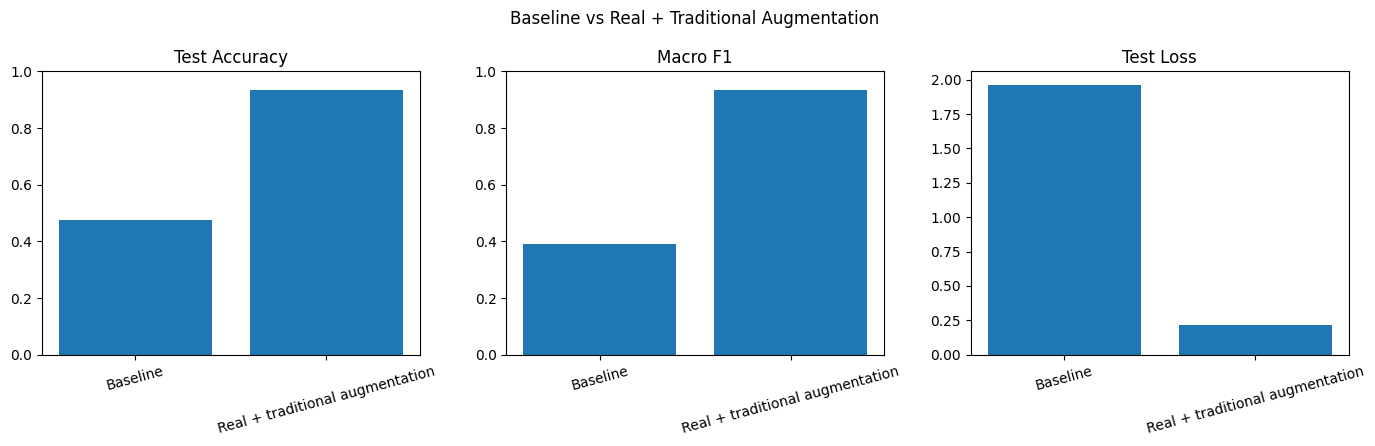

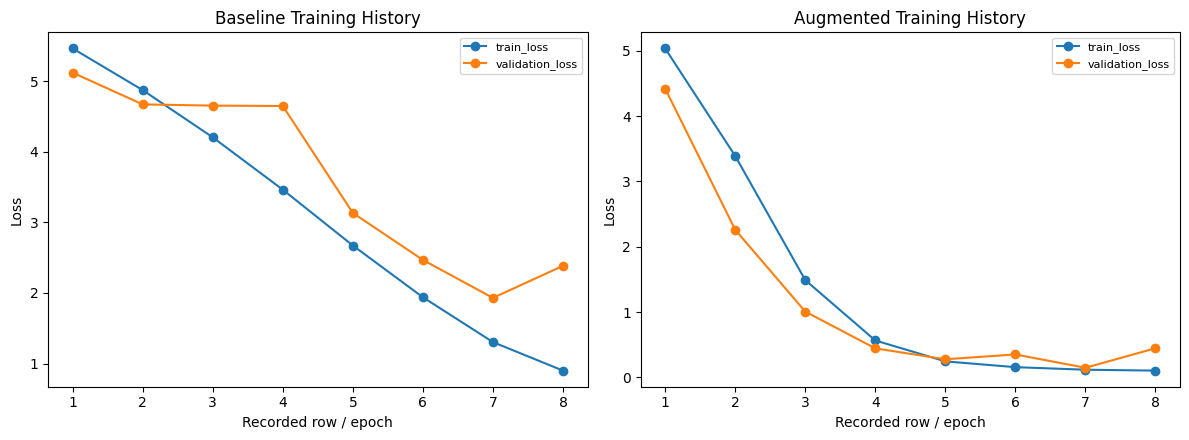

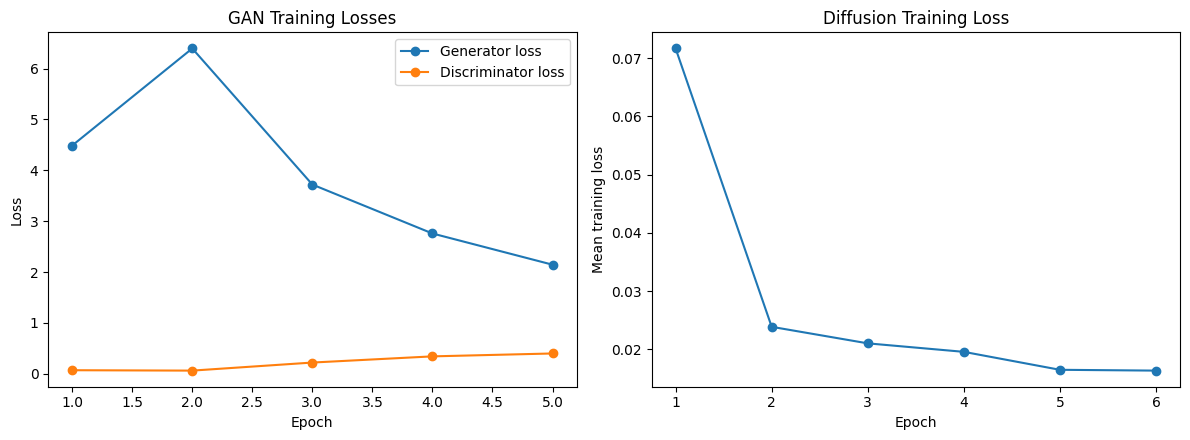

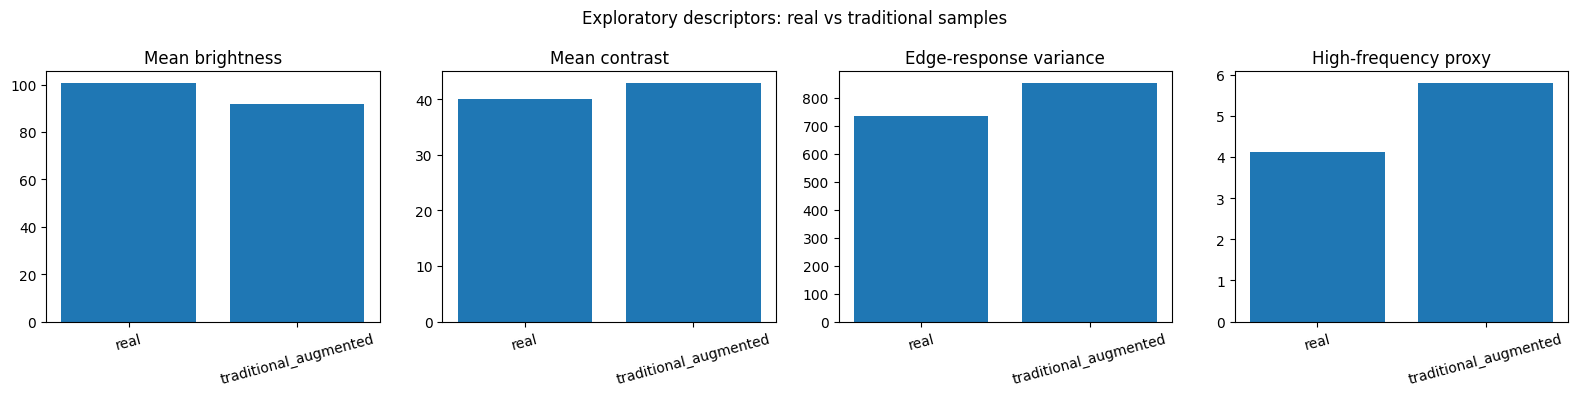

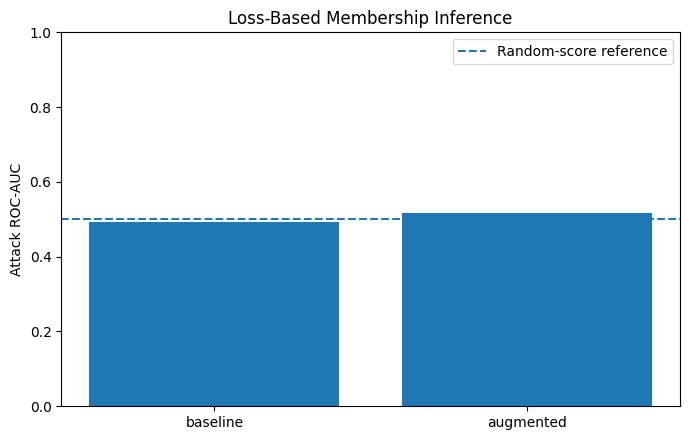


OUTPUT VERIFICATION
OK       GAN_Diffusion_Training_Comparison.png (80,428 bytes)
OK       Membership_Attack_Comparison.csv (1,057 bytes)
OK       Membership_Attack_Comparison.png (33,877 bytes)
OK       Notebook14_Conclusion.md (2,662 bytes)
OK       Notebook14_Summary.json (740 bytes)
OK       Real_vs_Traditional_Quality_Descriptors.png (69,443 bytes)
OK       Recognition_Comparison.csv (352 bytes)
OK       Recognition_Model_Comparison.png (62,944 bytes)
OK       Recognition_Training_Curves.png (93,281 bytes)

FINAL SUMMARY
                     experiment  training_images  test_images  test_accuracy  macro_precision  macro_recall  macro_f1  test_loss
                       Baseline             4243          778       0.474293         0.429560      0.442115  0.389701   1.962765
Real + traditional augmentation            12729          778       0.933162         0.953361      0.939231  0.935109   0.213802

Runtime: 2.58 seconds
ZIP: /kaggle/working/ubiris_v2_project/UBIRIS_V2_Notebook

/kaggle/working/ubiris_v2_project/notebook14_result_visualization_ablation/Notebook14_Conclusion.md

/kaggle/working/ubiris_v2_project/UBIRIS_V2_Notebook14_Results.zip

In [16]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# NOTEBOOK 14 — RESULT VISUALIZATION AND ABLATION STUDIES
# Uses saved outputs only; no model retraining.
# ============================================================
PROJECT = Path("/kaggle/working/ubiris_v2_project")
OUT = PROJECT / "notebook14_result_visualization_ablation"
OUT.mkdir(parents=True, exist_ok=True)
start = time.time()

def find_file(name):
    matches = [
        p for p in PROJECT.rglob(name)
        if OUT not in p.parents
    ]
    return matches[0] if matches else None

def read_json(name):
    p = find_file(name)
    if p is None:
        print("WARNING: missing", name)
        return None
    return json.loads(p.read_text(encoding="utf-8"))

def read_csv(name):
    p = find_file(name)
    if p is None:
        print("WARNING: missing", name)
        return None
    return pd.read_csv(p)

print("=" * 72)
print("NOTEBOOK 14 — RESULT VISUALIZATION AND ABLATION STUDIES")
print("=" * 72)

# 1. Load the recorded metrics
baseline = read_json("UBIRIS_V2_baseline_test_metrics.json")
augmented = read_json("UBIRIS_V2_augmented_recognition_test_metrics.json")
traditional = read_json("UBIRIS_V2_traditional_augmentation_summary.json")
membership = read_json("UBIRIS_V2_membership_attack_summary.json")
quality = read_csv("UBIRIS_V2_quality_diversity_summary.csv")
gan = read_csv("UBIRIS_V2_GAN_training_history.csv")
diffusion = read_csv("UBIRIS_V2_ddpm_training_history.csv")
baseline_history = read_csv("UBIRIS_V2_baseline_training_history.csv")
aug_history = read_csv("UBIRIS_V2_augmented_recognition_history.csv")

# 2. Recognition comparison
if baseline is None or augmented is None:
    raise FileNotFoundError("Baseline or augmented recognition metrics missing.")

comparison = pd.DataFrame([
    {
        "experiment": "Baseline",
        "training_images": baseline.get("training_images"),
        "test_images": baseline.get("test_images"),
        "test_accuracy": baseline.get("test_accuracy"),
        "macro_precision": baseline.get("test_macro_precision"),
        "macro_recall": baseline.get("test_macro_recall"),
        "macro_f1": baseline.get("test_macro_f1"),
        "test_loss": baseline.get("test_loss"),
    },
    {
        "experiment": "Real + traditional augmentation",
        "training_images": augmented.get("training_images"),
        "test_images": augmented.get("test_images"),
        "test_accuracy": augmented.get("test_accuracy"),
        "macro_precision": augmented.get("macro_precision"),
        "macro_recall": augmented.get("macro_recall"),
        "macro_f1": augmented.get("macro_f1"),
        "test_loss": augmented.get("test_loss"),
    }
])
comparison.to_csv(OUT / "Recognition_Comparison.csv", index=False)

# Accuracy, F1 and loss comparison
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].bar(comparison["experiment"], comparison["test_accuracy"])
axes[0].set_title("Test Accuracy")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(comparison["experiment"], comparison["macro_f1"])
axes[1].set_title("Macro F1")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=15)

axes[2].bar(comparison["experiment"], comparison["test_loss"])
axes[2].set_title("Test Loss")
axes[2].tick_params(axis="x", rotation=15)

fig.suptitle("Baseline vs Real + Traditional Augmentation")
fig.tight_layout()
fig.savefig(OUT / "Recognition_Model_Comparison.png", dpi=160)
plt.show()
plt.close(fig)

# 3. Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

if baseline_history is not None:
    for col in baseline_history.columns:
        if "loss" in col.lower() and pd.api.types.is_numeric_dtype(baseline_history[col]):
            axes[0].plot(
                np.arange(1, len(baseline_history) + 1),
                baseline_history[col], marker="o", label=col
            )
    axes[0].set_title("Baseline Training History")
    axes[0].set_xlabel("Recorded row / epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend(fontsize=8)

if aug_history is not None:
    for col in aug_history.columns:
        if "loss" in col.lower() and pd.api.types.is_numeric_dtype(aug_history[col]):
            axes[1].plot(
                np.arange(1, len(aug_history) + 1),
                aug_history[col], marker="o", label=col
            )
    axes[1].set_title("Augmented Training History")
    axes[1].set_xlabel("Recorded row / epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig(OUT / "Recognition_Training_Curves.png", dpi=160)
plt.show()
plt.close(fig)

# 4. GAN and diffusion learning curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

if gan is not None:
    if "generator_loss" in gan:
        axes[0].plot(gan["epoch"], gan["generator_loss"],
                     marker="o", label="Generator loss")
    if "discriminator_loss" in gan:
        axes[0].plot(gan["epoch"], gan["discriminator_loss"],
                     marker="o", label="Discriminator loss")
    axes[0].set_title("GAN Training Losses")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

if diffusion is not None:
    axes[1].plot(diffusion["epoch"], diffusion["mean_training_loss"],
                 marker="o")
    axes[1].set_title("Diffusion Training Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Mean training loss")

fig.tight_layout()
fig.savefig(OUT / "GAN_Diffusion_Training_Comparison.png", dpi=160)
plt.show()
plt.close(fig)

# 5. Quality/diversity comparison: only real and individual traditional images
# GAN/diffusion rows describe composite grids and are deliberately excluded.
quality_plot_path = OUT / "Real_vs_Traditional_Quality_Descriptors.png"
if quality is not None and "group" in quality.columns:
    usable = quality[
        quality["group"].astype(str).isin(["real", "traditional_augmented"])
    ].copy()
    if not usable.empty:
        metric_cols = [
            ("brightness_mean_mean", "Mean brightness"),
            ("contrast_std_mean", "Mean contrast"),
            ("edge_variance_sharpness_mean", "Edge-response variance"),
            ("high_frequency_noise_proxy_mean", "High-frequency proxy")
        ]
        available = [(c, label) for c, label in metric_cols if c in usable.columns]
        if available:
            fig, axes = plt.subplots(1, len(available),
                                     figsize=(4 * len(available), 4))
            if len(available) == 1:
                axes = [axes]
            for ax, (col, title) in zip(axes, available):
                ax.bar(usable["group"], usable[col])
                ax.set_title(title)
                ax.tick_params(axis="x", rotation=15)
            fig.suptitle("Exploratory descriptors: real vs traditional samples")
            fig.tight_layout()
            fig.savefig(quality_plot_path, dpi=160)
            plt.show()
            plt.close(fig)

# 6. Membership inference comparison
if membership is not None and membership.get("model_results"):
    mem_df = pd.DataFrame(membership["model_results"])
    if {"model", "attack_roc_auc"}.issubset(mem_df.columns):
        mem_df.to_csv(OUT / "Membership_Attack_Comparison.csv", index=False)
        plt.figure(figsize=(7, 4.5))
        plt.bar(mem_df["model"], mem_df["attack_roc_auc"])
        plt.axhline(0.5, linestyle="--", label="Random-score reference")
        plt.ylim(0, 1)
        plt.ylabel("Attack ROC-AUC")
        plt.title("Loss-Based Membership Inference")
        plt.legend()
        plt.tight_layout()
        plt.savefig(OUT / "Membership_Attack_Comparison.png", dpi=160)
        plt.show()
        plt.close()

# 7. Honest ablation interpretation
accuracy_delta = (
    float(augmented["test_accuracy"]) - float(baseline["test_accuracy"])
)
f1_delta = (
    float(augmented["macro_f1"]) - float(baseline["test_macro_f1"])
)
auc_text = ""
if membership is not None:
    auc_text = "\n".join(
        f"- {r['model']}: ROC-AUC {r['attack_roc_auc']:.4f}"
        for r in membership.get("model_results", [])
    )

report = f"""# Notebook 14 — Result Visualization and Ablation Studies

## Recognition comparison

| Experiment | Test accuracy | Macro precision | Macro recall | Macro F1 | Test loss |
|---|---:|---:|---:|---:|---:|
| Baseline | {baseline['test_accuracy']:.4f} | {baseline['test_macro_precision']:.4f} | {baseline['test_macro_recall']:.4f} | {baseline['test_macro_f1']:.4f} | {baseline['test_loss']:.4f} |
| Real + traditional augmentation | {augmented['test_accuracy']:.4f} | {augmented['macro_precision']:.4f} | {augmented['macro_recall']:.4f} | {augmented['macro_f1']:.4f} | {augmented['test_loss']:.4f} |

Observed difference in test accuracy: {accuracy_delta * 100:.2f} percentage points.
Observed difference in macro F1: {f1_delta * 100:.2f} percentage points.

These are comparisons between recorded experiments, not a controlled causal
ablation. The augmented experiment uses more training examples, and other
training details/checkpoints must be verified before attributing the full
difference to augmentation alone.

## GAN and diffusion
- GAN training: {len(gan) if gan is not None else 0} recorded epochs.
- Diffusion training: {len(diffusion) if diffusion is not None else 0} recorded epochs.
- The saved GAN preview was described as repetitive/grid-like with artifacts.
- The saved diffusion preview was described as cloudy/noisy and not recognizably ocular.
- Decreasing training loss alone does not demonstrate realistic images or
  identity preservation.

## Membership inference
{auc_text if auc_text else "Membership attack summary unavailable."}

ROC-AUC near 0.5 indicates little member/non-member separation by this score
under the tested setup. It does not prove privacy.

## Quality/diversity
Quality descriptors are exploratory. Composite GAN/diffusion preview-grid
statistics are not treated as individual-image quality metrics.

## Limitations
- The data split is image-level, not subject-disjoint.
- Identity labels were parsed from filenames and not independently verified.
- GAN and diffusion individual generated samples were unavailable for a fair
  image-level recognition ablation.
- No confidence intervals or repeated random-seed runs were performed here.
- Notebook 12 reported extremely low prediction accuracy while Notebook 10
  reported much higher accuracy. This inconsistency requires auditing
  checkpoint loading, preprocessing, class mapping, and evaluation split.
- This notebook visualizes existing outputs; it does not retrain models or
  establish causal effects.

## Conclusion
Traditional augmentation's recorded experiment achieved higher recognition
metrics than the recorded baseline, but the magnitude of the difference needs
independent reproducibility checks. The saved GAN and diffusion experiments
did not produce convincing ocular samples in their previews. The privacy
results are limited to one loss-based membership attack. Subject-disjoint
evaluation, stronger generated-image metrics, and repeatable controlled
experiments are needed before claiming improved biometric robustness or privacy.
"""
(OUT / "Notebook14_Conclusion.md").write_text(report, encoding="utf-8")

summary = {
    "notebook": 14,
    "title": "Result Visualization and Ablation Studies",
    "retrained_models": False,
    "baseline_test_accuracy": baseline["test_accuracy"],
    "augmented_test_accuracy": augmented["test_accuracy"],
    "accuracy_difference_percentage_points": accuracy_delta * 100,
    "baseline_macro_f1": baseline["test_macro_f1"],
    "augmented_macro_f1": augmented["macro_f1"],
    "macro_f1_difference": f1_delta,
    "gan_epochs": len(gan) if gan is not None else None,
    "diffusion_epochs": len(diffusion) if diffusion is not None else None,
    "limitations": [
        "Image-level, not subject-disjoint split",
        "Filename-derived provisional identity labels",
        "GAN/diffusion previews not convincingly ocular",
        "No causal claim from cross-experiment metric differences",
        "Recognition evaluation discrepancy requires auditing"
    ]
}
(OUT / "Notebook14_Summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)

# 8. Verify and ZIP all Notebook 14 artifacts
print("\nOUTPUT VERIFICATION")
outputs = [p for p in OUT.iterdir() if p.is_file()]
for p in sorted(outputs):
    print(f"{'OK' if p.stat().st_size > 0 else 'EMPTY':8} {p.name} ({p.stat().st_size:,} bytes)")

zip_path = PROJECT / "UBIRIS_V2_Notebook14_Results.zip"
with ZipFile(zip_path, "w", ZIP_DEFLATED) as zf:
    for p in sorted(outputs):
        zf.write(p, arcname=p.relative_to(PROJECT))

with ZipFile(zip_path, "r") as zf:
    bad = zf.testzip()
    if bad:
        raise RuntimeError(f"ZIP integrity failure: {bad}")
    count = len(zf.namelist())

print("\nFINAL SUMMARY")
print(comparison.to_string(index=False))
print(f"\nRuntime: {time.time() - start:.2f} seconds")
print("ZIP:", zip_path)
print("Archived files:", count)
print("ZIP integrity: PASSED")
display(FileLink(str(OUT / "Notebook14_Conclusion.md")))
display(FileLink(str(zip_path)))
